# Задание 1. Функции активации и инициализация

Сеть — `BaseNetwork` из условия (784 → 512 → 256 → 256 → 128 → 10).
Функции активации: **ReLU, Tanh, Identity** и дополнительно **Sigmoid** (пункт со звёздочкой).

Инициализации весов (смещения везде нулевые):
- `const` — все веса равны 0.01;
- `normal(0.01)` — $\mathcal N(0, 0.01^2)$, «слишком маленькая»;
- `normal(1)` — $\mathcal N(0, 1)$, «слишком большая»;
- `xavier` — $\mathcal N(0, \frac{2}{n_{in}+n_{out}})$, сохраняет дисперсию для линейных/симметричных активаций;
- `kaiming` — $\mathcal N(0, \frac{2}{n_{in}})$, учитывает, что ReLU зануляет половину входов.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from common import BaseNetwork, load_fashion_mnist, train

torch.manual_seed(0)
data = load_fashion_mnist()
x_train, y_train, x_test, y_test = data

ACTS = {"ReLU": nn.ReLU, "Tanh": nn.Tanh, "Identity": nn.Identity, "Sigmoid": nn.Sigmoid}
INITS = {
    "const": lambda w: nn.init.constant_(w, 0.01),
    "normal(0.01)": lambda w: nn.init.normal_(w, std=0.01),
    "normal(1)": lambda w: nn.init.normal_(w, std=1.0),
    "xavier": nn.init.xavier_normal_,
    "kaiming": lambda w: nn.init.kaiming_normal_(w, nonlinearity="relu"),
}


def make_model(act, init, seed=0):
    torch.manual_seed(seed)
    model = BaseNetwork(ACTS[act]())
    for m in model.modules():
        if isinstance(m, nn.Linear):
            INITS[init](m.weight)
            nn.init.zeros_(m.bias)
    return model

## Активации и градиенты по слоям

Прогоняем через необученную сеть батч из 1024 картинок и сохраняем:
- выход каждого слоя (после функции активации; для последнего слоя это логиты);
- градиент функции потерь по весам каждого `Linear`.

In [2]:
def layer_stats(model, x, y):
    acts, h = [], x
    for layer in model.layers:
        h = layer(h)
        if not isinstance(layer, nn.Linear) or layer is model.layers[-1]:
            acts.append(h.detach().flatten())
    F.cross_entropy(h, y).backward()
    grads = [m.weight.grad.flatten() for m in model.layers if isinstance(m, nn.Linear)]
    return acts, grads


xb, yb = x_train[:1024], y_train[:1024]
stats = {(a, i): layer_stats(make_model(a, i), xb, yb) for a in ACTS for i in INITS}

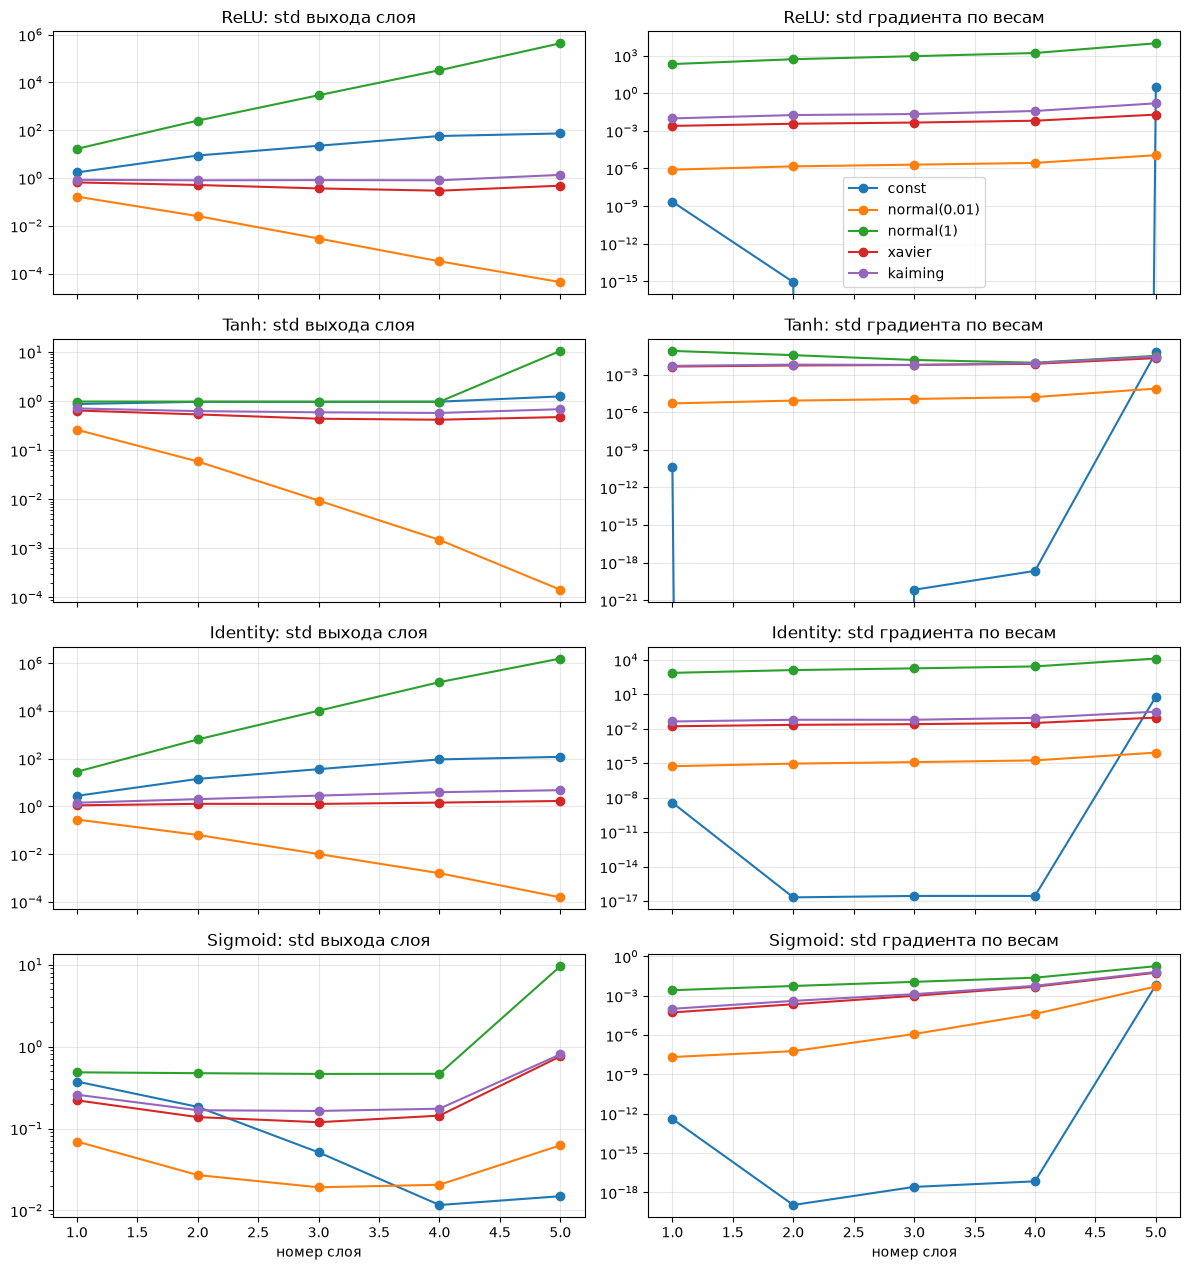

In [3]:
fig, axes = plt.subplots(len(ACTS), 2, figsize=(12, 3.2 * len(ACTS)), sharex=True)
layers = np.arange(1, 6)
for row, act in zip(axes, ACTS):
    for init in INITS:
        acts, grads = stats[(act, init)]
        row[0].plot(layers, [a.std().item() for a in acts], "o-", label=init)
        row[1].plot(layers, [g.std().item() for g in grads], "o-", label=init)
    row[0].set_title(f"{act}: std выхода слоя")
    row[1].set_title(f"{act}: std градиента по весам")
    for ax in row:
        ax.set_yscale("log")
        ax.grid(alpha=0.3)
axes[0, 1].legend()
for ax in axes[-1]:
    ax.set_xlabel("номер слоя")
plt.tight_layout()
plt.show()

Гистограммы тех же величин для каждого слоя (строки — инициализации, столбцы — слои).

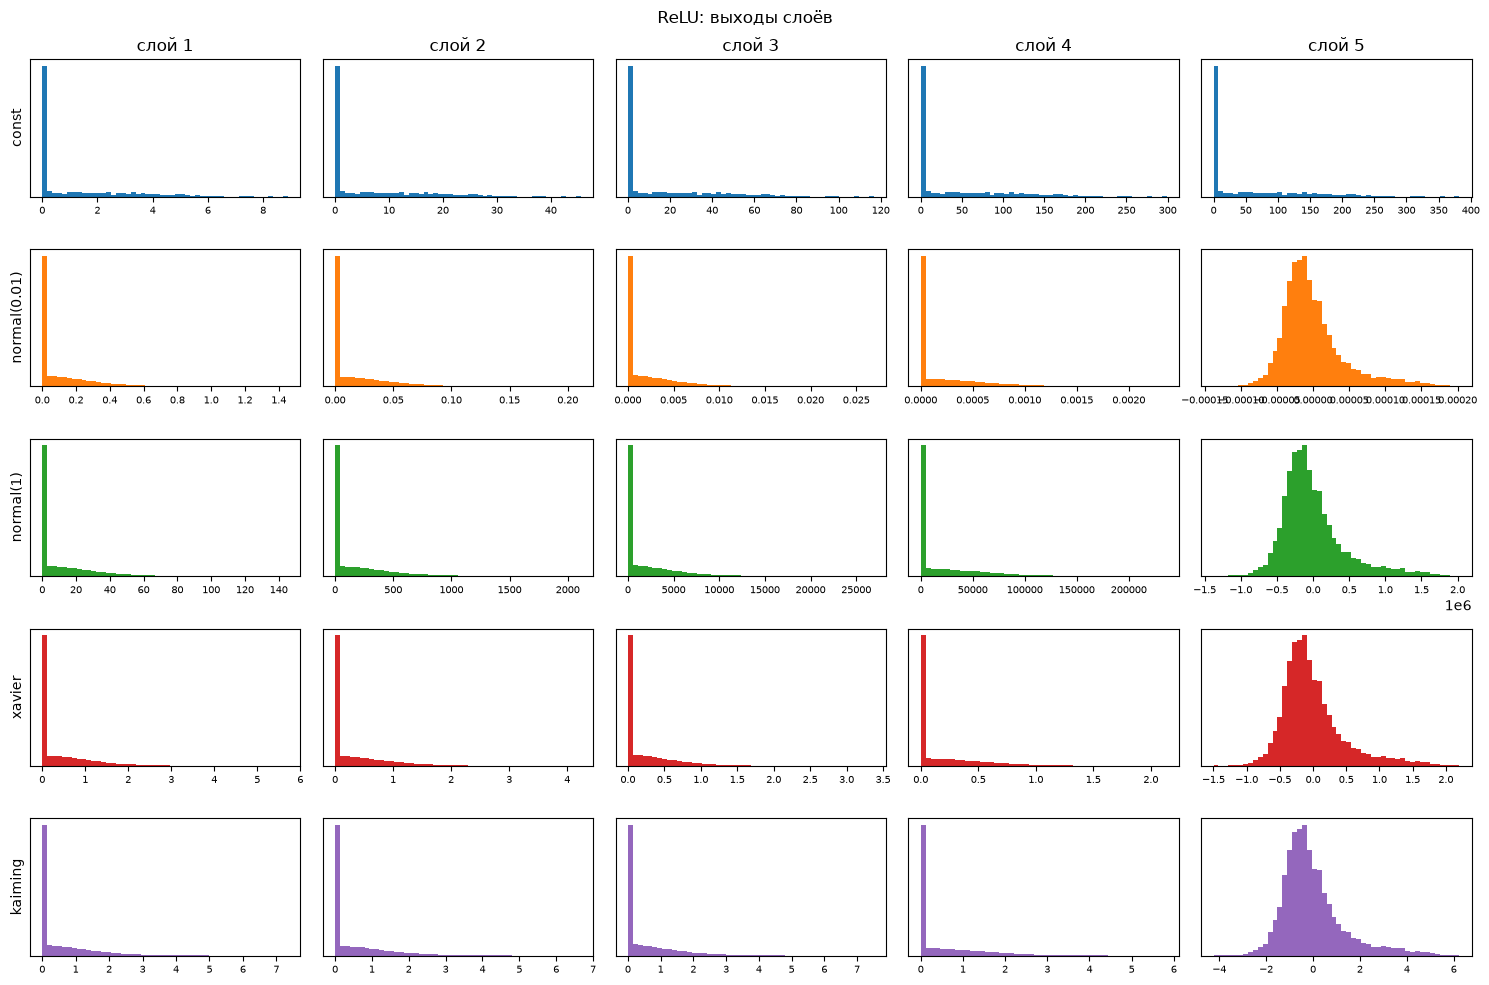

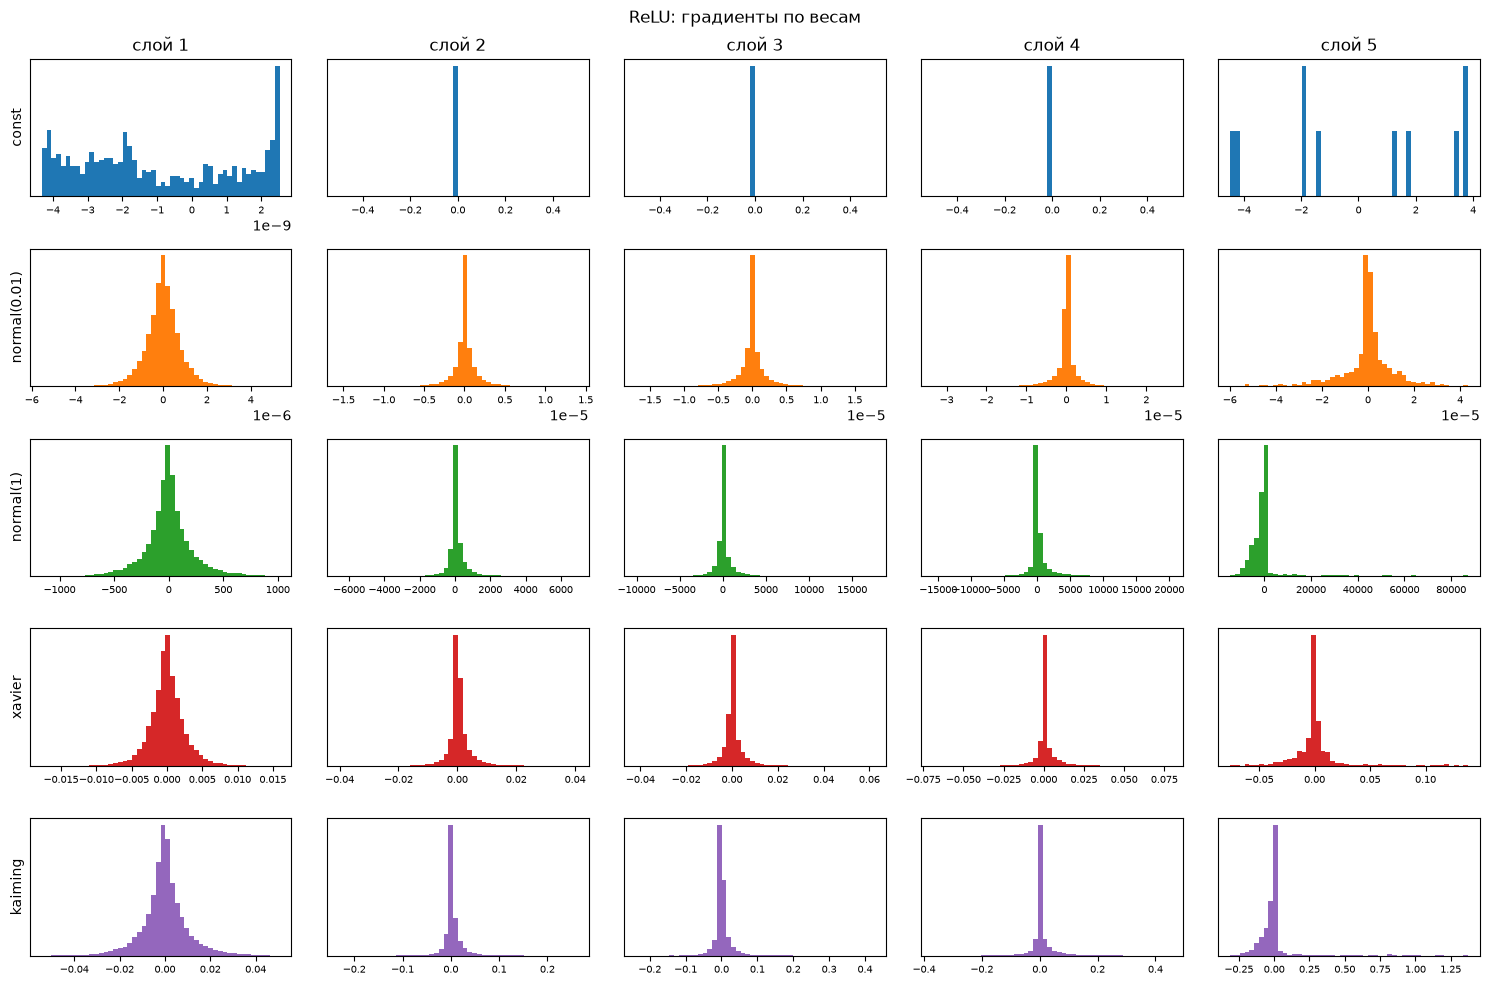

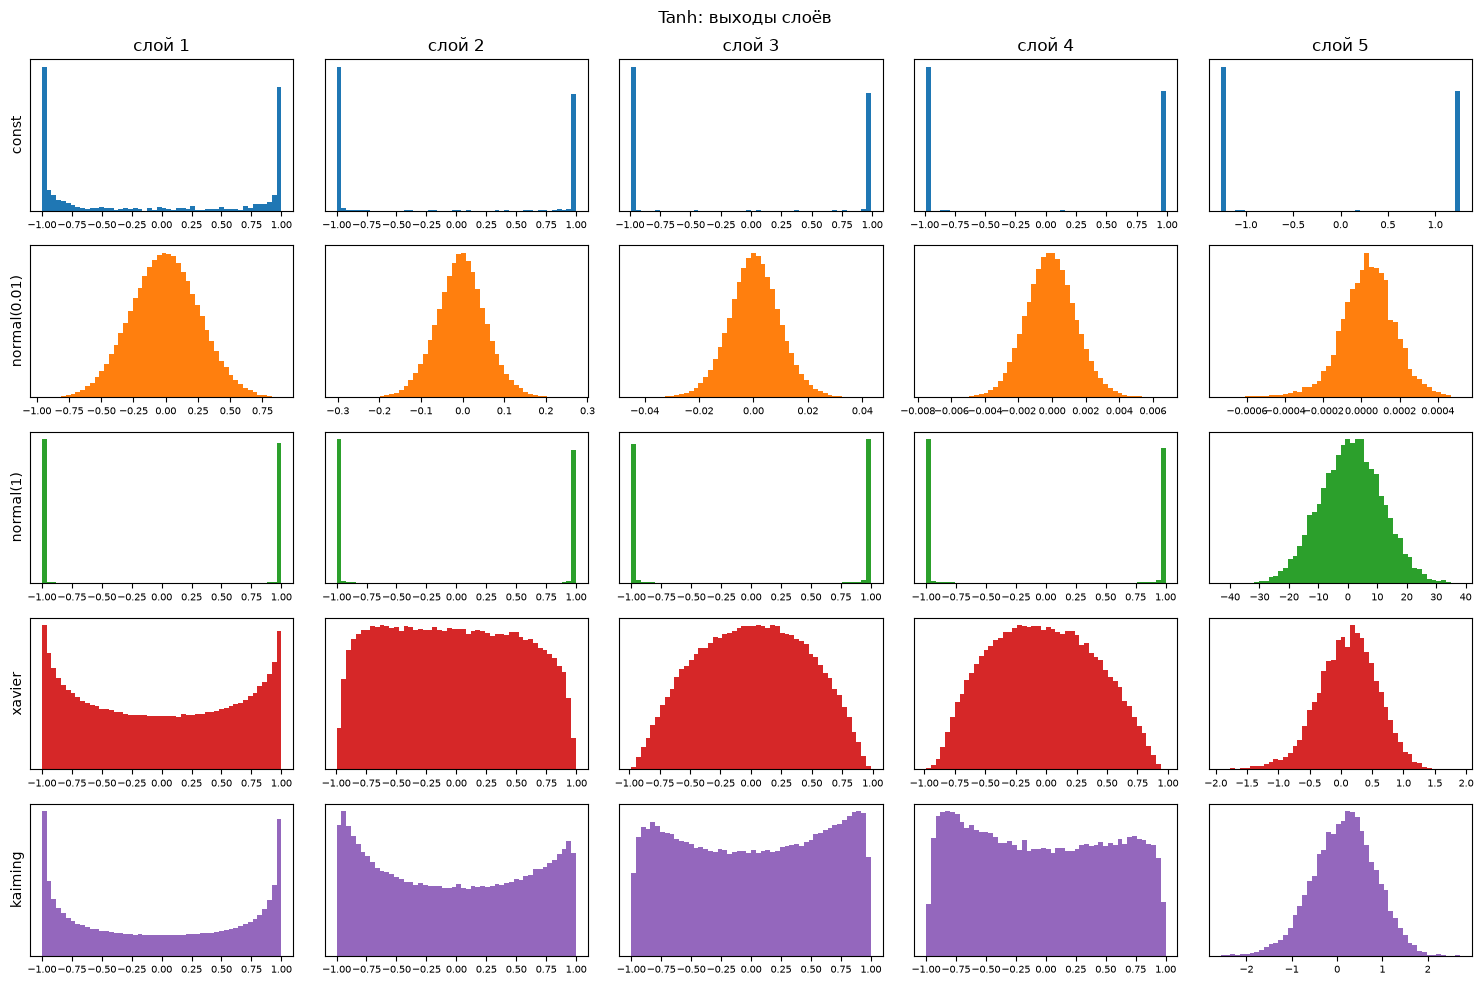

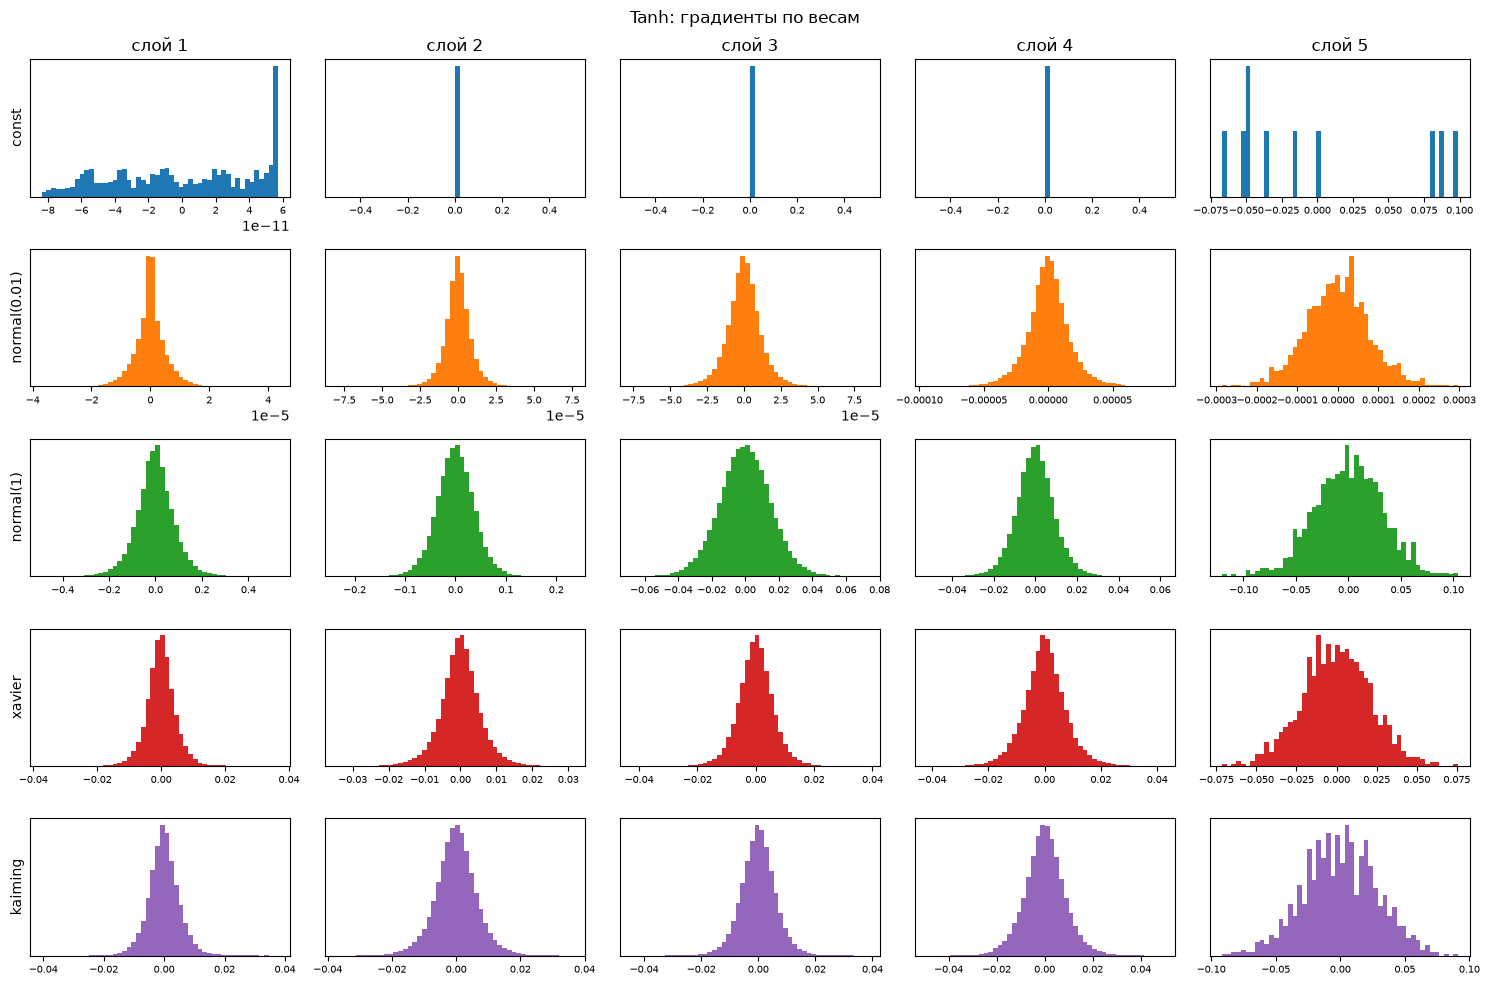

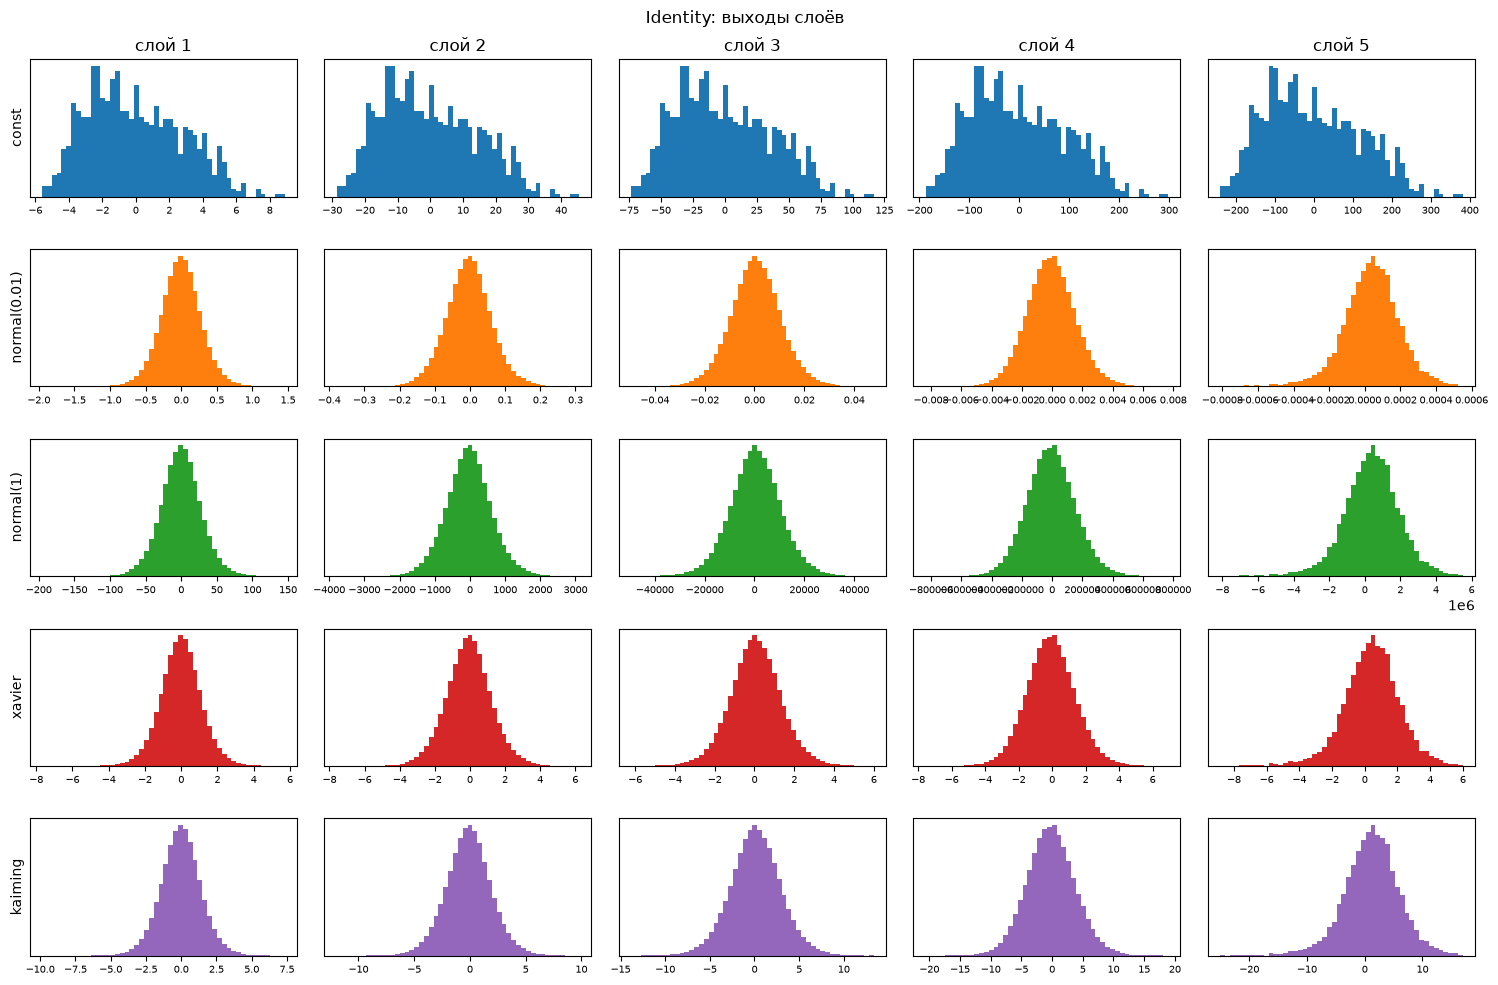

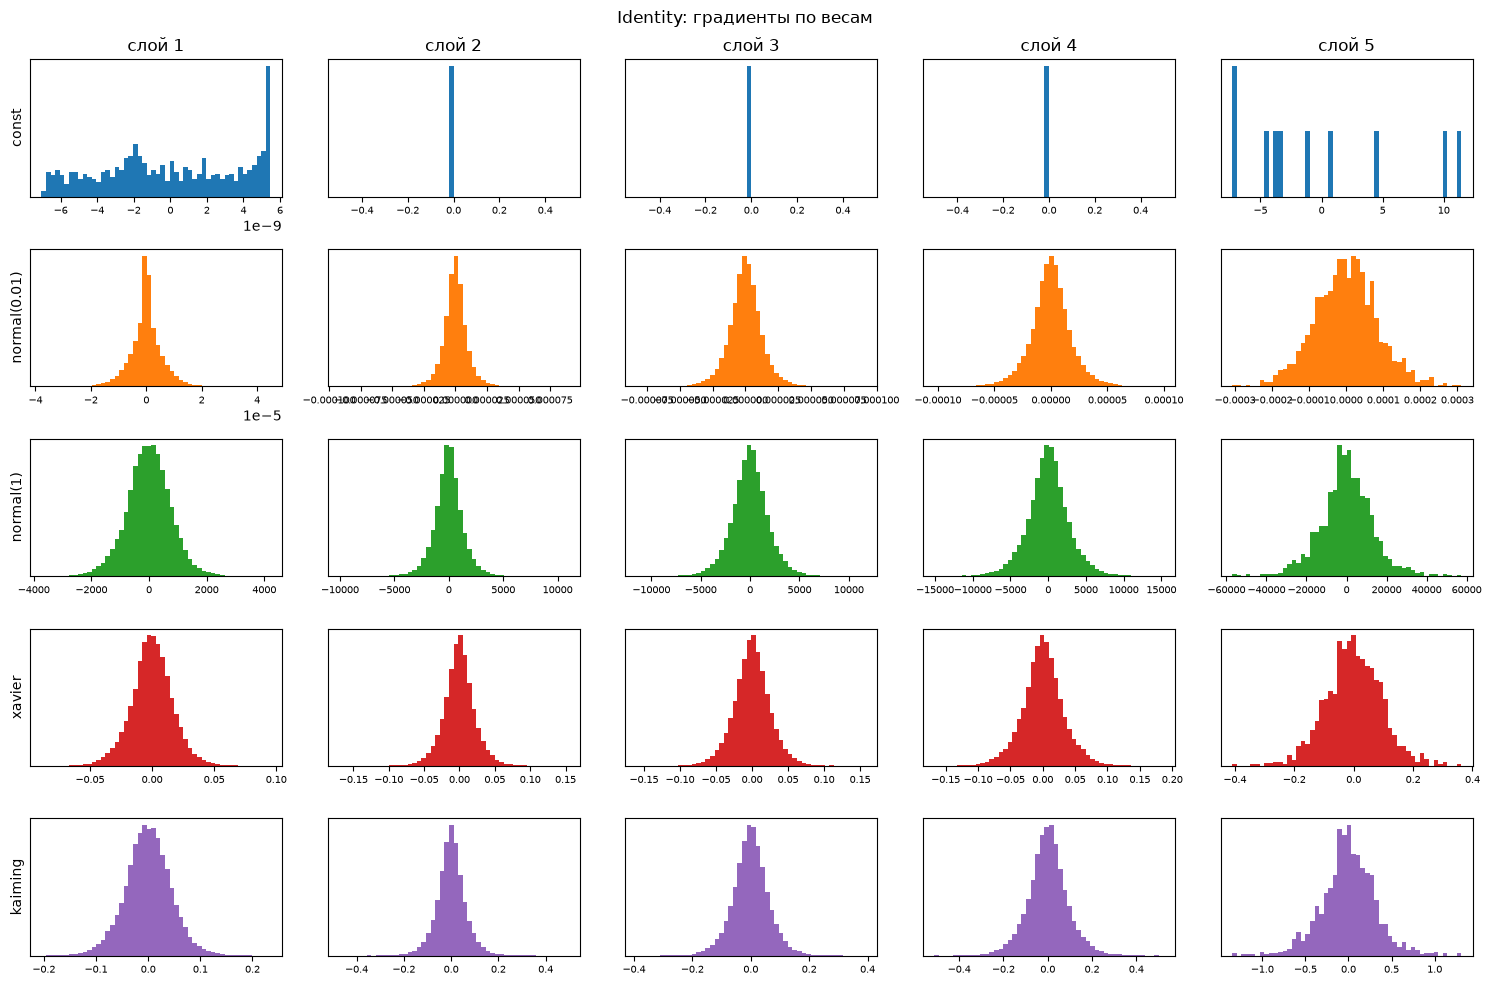

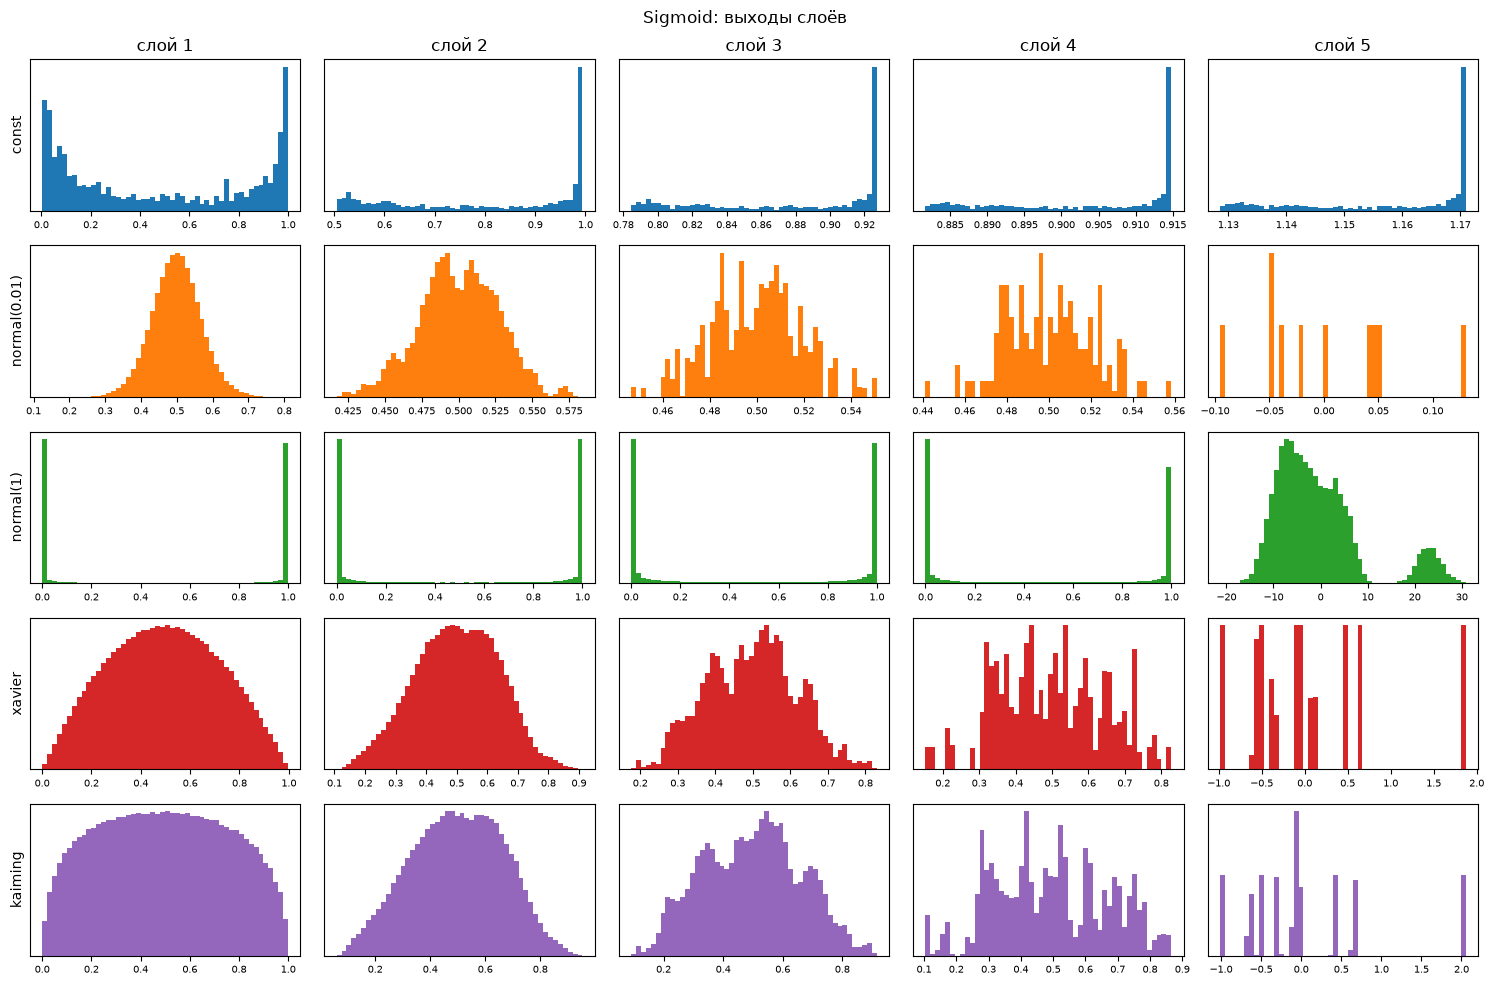

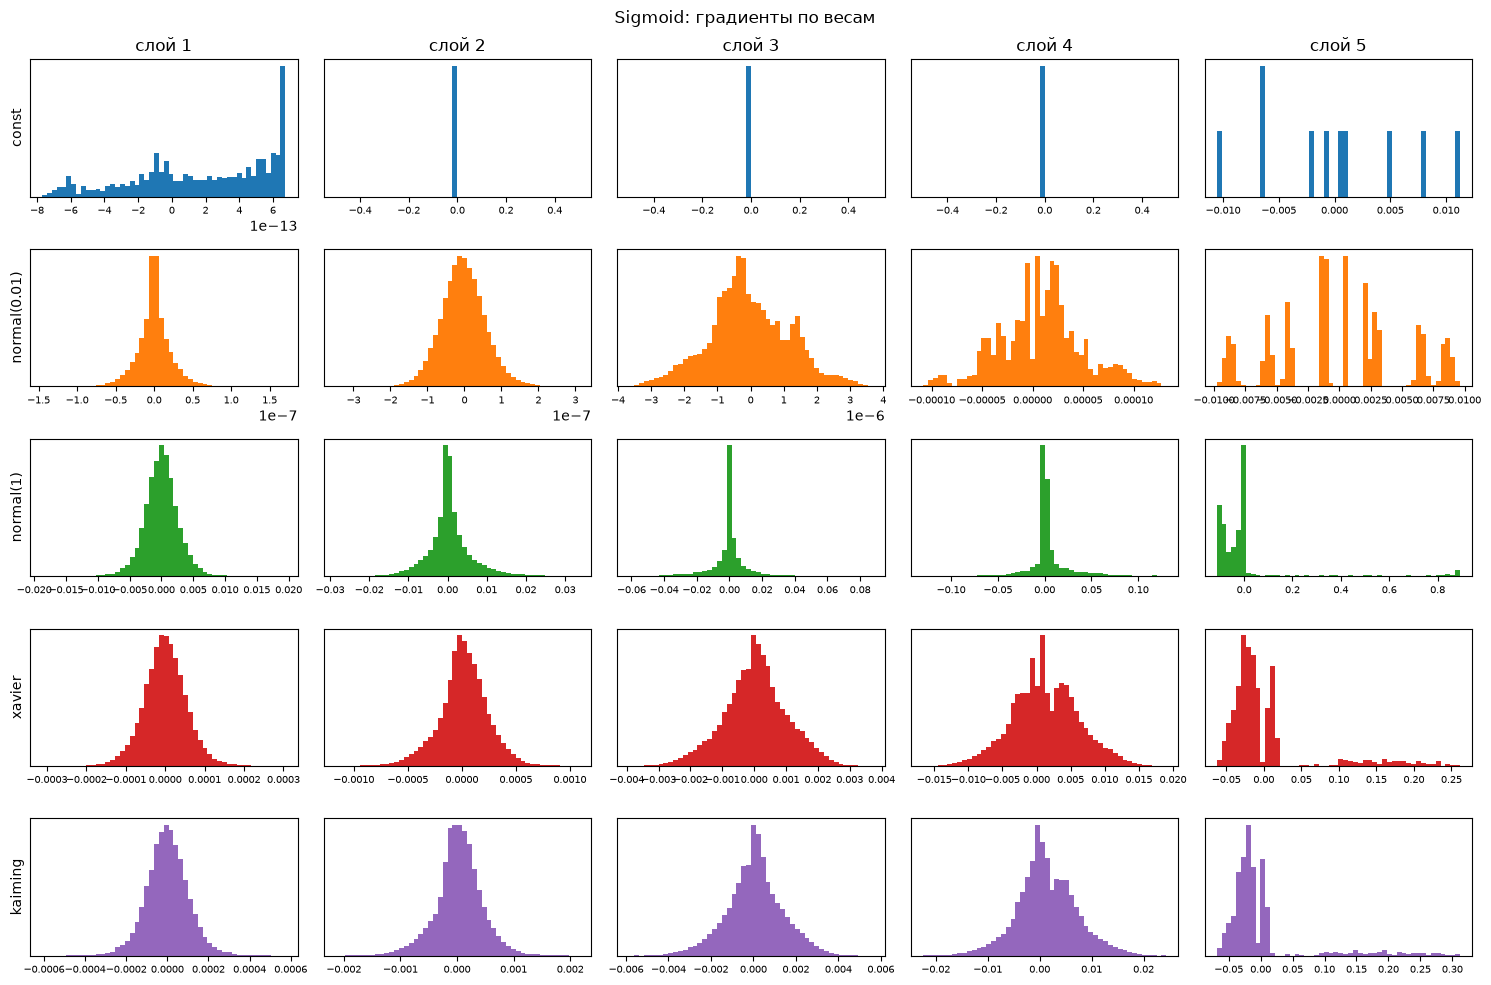

In [4]:
def plot_histograms(act, kind):
    idx = 0 if kind == "act" else 1
    fig, axes = plt.subplots(len(INITS), 5, figsize=(15, 2 * len(INITS)))
    for r, init in enumerate(INITS):
        for c, values in enumerate(stats[(act, init)][idx]):
            ax = axes[r, c]
            ax.hist(values.numpy(), bins=50, color=f"C{r}")
            ax.set_yticks([])
            ax.tick_params(labelsize=7)
            if r == 0:
                ax.set_title(f"слой {c + 1}")
            if c == 0:
                ax.set_ylabel(init)
    title = "выходы слоёв" if kind == "act" else "градиенты по весам"
    fig.suptitle(f"{act}: {title}")
    plt.tight_layout()
    plt.show()


for act in ACTS:
    plot_histograms(act, "act")
    plot_histograms(act, "grad")

## Сходимость на FashionMNIST (SGD)

Для каждой пары (активация, инициализация) обучаем 3 эпохи обычным SGD (lr = 0.02, batch = 128).
При lr = 0.05 глубокая линейная сеть (Identity) расходится в NaN даже с xavier, поэтому шаг чуть меньше.

In [5]:
results = {}
for act in ACTS:
    for init in INITS:
        model = make_model(act, init)
        results[(act, init)] = train(model, torch.optim.SGD(model.parameters(), lr=0.02), data, epochs=3)

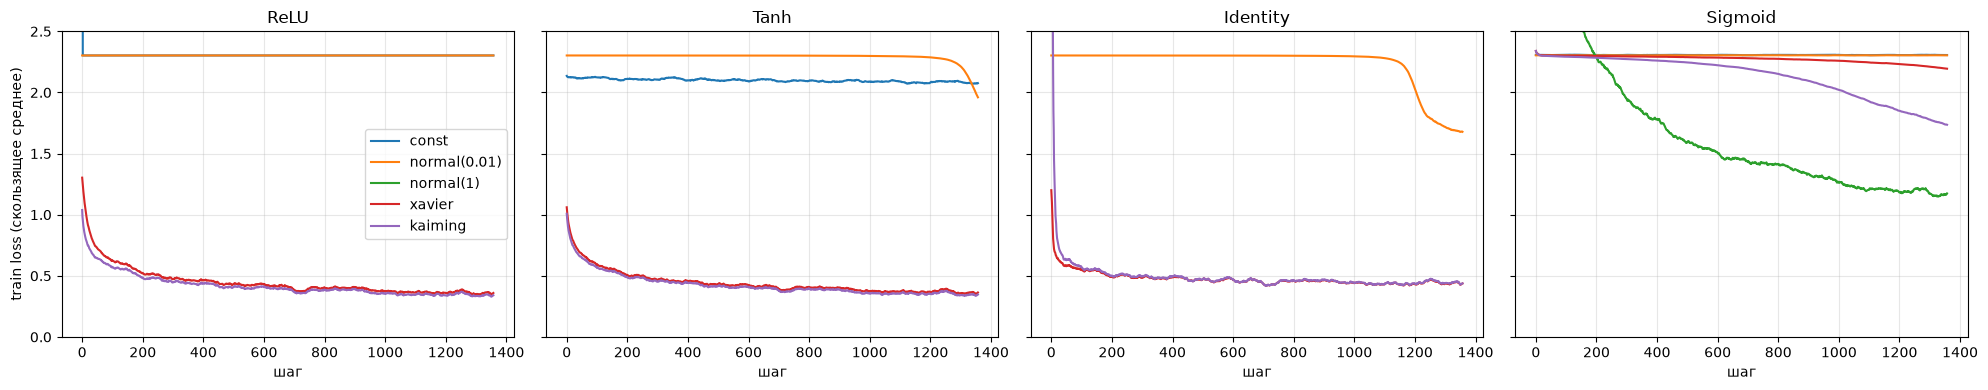

Точность на тесте после 3 эпох (* — loss ушёл в NaN):


,const,normal(0.01),normal(1),xavier,kaiming
ReLU,0.100,0.100,0.100 *,0.858,0.857
Tanh,0.171,0.200,0.544,0.860,0.862
Identity,0.100 *,0.208,0.100 *,0.834,0.832
Sigmoid,0.100,0.100,0.589,0.293,0.467


In [6]:
def smooth(values, k=50):
    values = np.asarray(values, dtype=float)
    return np.convolve(values, np.ones(k) / k, mode="valid")


fig, axes = plt.subplots(1, len(ACTS), figsize=(5 * len(ACTS), 4), sharey=True)
for ax, act in zip(axes, ACTS):
    for init in INITS:
        ax.plot(smooth(results[(act, init)]["loss"]), label=init)
    ax.set_title(act)
    ax.set_xlabel("шаг")
    ax.set_ylim(0, 2.5)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("train loss (скользящее среднее)")
axes[0].legend()
plt.tight_layout()
plt.show()

def final_acc(act, init):
    h = results[(act, init)]
    mark = "" if np.isfinite(h["loss"][-1]) else " *"
    return f"{h['test_acc'][-1]:.3f}{mark}"


print("Точность на тесте после 3 эпох (* — loss ушёл в NaN):")
pd.DataFrame({init: [final_acc(act, init) for act in ACTS] for init in INITS}, index=list(ACTS))

## Выводы

Главное правило: при хорошей инициализации **дисперсия выходов и градиентов примерно постоянна от слоя к слою**.
Если она на каждом слое умножается на $k \ne 1$, то через $L$ слоёв получаем $k^L$: затухание или взрыв.

| инициализация | что происходит |
|---|---|
| `const` | Все нейроны слоя получают одинаковые веса, поэтому считают одно и то же и получают одинаковые градиенты. Симметрия не ломается, и сеть фактически состоит из одного нейрона на слой. Градиенты внутренних слоёв почти нулевые (1e-15…1e-20), сеть не учится (≈10–17 %). С Identity выход растёт и loss уходит в NaN. |
| `normal(0.01)` | Слишком маленькие веса: std выхода падает примерно в 5–10 раз на каждом слое (до 1e-4 на выходе), градиенты порядка 1e-6. Это **затухание**: ReLU и Sigmoid за 3 эпохи вообще не сдвинулись с loss = ln 10, а Tanh и Identity «просыпаются» только к концу третьей эпохи. |
| `normal(1)` | Слишком большие веса. Для ReLU и Identity — **взрыв** (std до 1e6 на выходе, градиенты до 1e3–1e4, loss = NaN). Tanh и Sigmoid почти всё время в насыщении (выходы ±1 или 0/1 на гистограммах), поэтому учатся медленно и нестабильно. |
| `xavier` | Для **Tanh** и **Identity** std выходов и градиентов почти одинаковый на всех слоях (≈0.5–1). Для них эта инициализация и выведена: производная в нуле равна 1. Для ReLU std немного падает с глубиной (ReLU зануляет половину сигнала), но при 5 слоях это не мешает. |
| `kaiming` | Для **ReLU** std выхода ≈ 1 на всех слоях: множитель 2 в $\frac{2}{n_{in}}$ компенсирует зануление половины входов. Для Tanh тоже работает хорошо, для Identity std медленно растёт (×√2 на слой). |

**Стабильные комбинации:** ReLU — kaiming (xavier почти так же хорошо), Tanh — xavier/kaiming,
Identity — xavier. На FashionMNIST с SGD именно они сходятся быстро: ≈0.86 точности за 3 эпохи.
Identity даже с хорошей инициализацией упирается в ≈0.83, потому что это просто линейная модель.

**Sigmoid (доп. пункт).** Ни одна стандартная инициализация не даёт хорошего результата. Выход сигмоиды не центрирован
(среднее 0.5), а производная не больше 1/4, поэтому градиент затухает к первым слоям (на графике std градиента
растёт от 1-го к 5-му слою примерно на 2–3 порядка). Лучше всех за 3 эпохи — `normal(1)` (0.59), затем `kaiming` (0.47),
`xavier` (0.29): для сигмоиды нужен std примерно в 4 раза больше, чем у Xavier. В глубоких сетях сигмоиду поэтому
почти не используют.